# 04 — Realisable against theoretical

Perfect foresight is the upper bound: it solves each trading day knowing every price in advance. No strategy can beat it on the same data.

The rolling-horizon strategies re-optimise every half hour on a **forecast** of the next 24 hours, commit only the next half hour, and are then **settled on actual prices**. Three deliberately naive forecasts are used — persistence, same time yesterday, and same interval last week — because a naive forecast is the honest floor. Anything a trading desk does better than that is upside the model should not assume.

Parameters were designed on 2024 and frozen in `src.strategies.FROZEN_CONFIG`. 2025 and 2026 are run with those values unchanged; `frozen_for()` is the only way the pipeline builds a configuration, and it ignores the year, so the no-tuning claim is enforced in code rather than promised.

Compute: `scripts/run_strategies.py` writes `outputs/strategy_daily.parquet`. This notebook reads it.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import cases, strategies, viz
from src.paths import OUTPUTS

viz.use_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

RECOMPUTE = False  # set True for a cold run; takes roughly 20 minutes

if RECOMPUTE or not (OUTPUTS / "strategy_daily.parquet").exists():
    subprocess.run(
        [sys.executable, "scripts/run_strategies.py"], cwd=Path.cwd().parent, check=True
    )

daily = pd.read_parquet(OUTPUTS / "strategy_daily.parquet")
daily["trading_date"] = pd.to_datetime(daily["trading_date"])
daily["year"] = daily["trading_date"].dt.year
print(f"{len(daily):,} daily rows")
print(f"cases      {sorted(daily['case'].unique())}")
print(f"strategies {sorted(daily['strategy'].unique())}")
print(f"period     {daily['trading_date'].min().date()} to {daily['trading_date'].max().date()}")

26,832 daily rows
cases      ['1h_credits', '1h_merchant', '2h_credits', '2h_merchant', '4h_credits', '4h_merchant']
strategies ['last_week', 'perfect_foresight', 'persistence', 'yesterday']
period     2023-10-01 to 2026-11-01


## The frozen configuration

In [2]:
config = strategies.FROZEN_CONFIG
pd.Series(
    {
        "design year": strategies.DESIGN_YEAR,
        "horizon (intervals)": config.horizon_intervals,
        "horizon (hours)": config.horizon_intervals * 5 / 60,
        "commit (intervals)": config.commit_intervals,
        "commit (minutes)": config.commit_intervals * 5,
        "energy forecasts": ", ".join(strategies.NAIVE_FORECASTS),
        "FCESS forecast": f"trailing mean over {strategies.FCESS_FORECAST_LOOKBACK // 288} days",
        "terminal state of charge": "free within bounds",
    }
).to_frame("value")

,value
design year,2024
horizon (intervals),288
horizon (hours),24.0
commit (intervals),6
commit (minutes),30
energy forecasts,"persistence, yesterday, last_week"
FCESS forecast,trailing mean over 7 days
terminal state of charge,free within bounds


The FCESS price gets a trailing mean rather than the energy forecast rule. FCESS clears at exactly zero in a large share of intervals, so a persistence forecast taken at such an interval predicts zero across the whole horizon and the battery declines to offer at all. That is not how a price taker behaves: it offers its available capacity and is paid whatever clears, because holding a few MW of reserve out of a hundred costs almost no headroom. The trailing mean is causal and uses no information from the future.

Enablement *ceilings* are taken as actual in every strategy, including perfect foresight, because whether a battery is enabled is AEMO's dispatch decision rather than the operator's. The capture rate therefore measures what forecast error costs on the **energy** side, which is where the operator's judgement actually bites.

## The bound holds

Checked before anything else is read off these numbers. Perfect foresight closes the state of charge every day while the rolling horizon carries it across days, so a single day can exceed the bound by borrowing from its neighbour; the period total cannot.

In [3]:
checks = []
for case in sorted(daily["case"].unique()):
    subset = daily[daily["case"] == case]
    bound = subset[subset["strategy"] == "perfect_foresight"].set_index("trading_date")
    for strategy in strategies.NAIVE_FORECASTS:
        realisable = subset[subset["strategy"] == strategy].set_index("trading_date")
        check = strategies.check_bound(realisable, bound)
        check.update({"case": case, "strategy": strategy})
        checks.append(check)

bound_checks = pd.DataFrame(checks).set_index(["case", "strategy"])
assert bound_checks["bound_holds"].all(), "a strategy beat the perfect-foresight bound"
print("perfect foresight is never beaten over the period, in any case\n")
bound_checks[["days", "realisable_total", "bound_total", "days_above_bound"]].round(0)

perfect foresight is never beaten over the period, in any case



days  realisable_total  bound_total  days_above_bound
case        strategy                                                          
1h_credits  persistence  1118         9055353.0   43491008.0                 6
            yesterday    1118        15133521.0   43491008.0                34
            last_week    1118        12802311.0   43491008.0                35
1h_merchant persistence  1118         8595034.0   45392055.0                 0
            yesterday    1118        14374979.0   45392055.0                30
            last_week    1118        11925826.0   45392055.0                27
2h_credits  persistence  1118        10475716.0   59240907.0                 5
            yesterday    1118        25258831.0   59240907.0                68
            last_week    1118        21641205.0   59240907.0                57
2h_merchant persistence  1118         8604125.0   61485757.0                 0
            yesterday    1118        24196873.0   61485757.0                60
            last_week    1118        20431065.0   61485757.0                47
4h_credits  persistence  1118        13697664.0   74100729.0                 4
            yesterday    1118        39870050.0   74100729.0               150
            last_week    1118        35502095.0   74100729.0               123
4h_merchant persistence  1118         8645058.0   77569915.0                 0
            yesterday    1118        39105249.0   77569915.0               133
            last_week    1118        33782294.0   77569915.0                98

Individual days above the bound are expected and are the state-of-charge carry-over described above, not a violation.

## Annual revenue and capture rates

2023 covers October to December and 2026 runs to the most recent complete trading day, so neither is a full year. Capture rates are comparable across years; totals are not.

In [4]:
annual = (
    daily.groupby(["case", "strategy", "year"], observed=True)
    .agg(
        days=("trading_date", "nunique"),
        total=("total_revenue", "sum"),
        energy=("energy_revenue", "sum"),
        fcess=("fcess_revenue", "sum"),
        cycles=("cycles", "sum"),
    )
    .reset_index()
)
bound = annual[annual["strategy"] == "perfect_foresight"].set_index(["case", "year"])
annual["bound"] = annual.set_index(["case", "year"]).index.map(bound["total"])
annual["bound_energy"] = annual.set_index(["case", "year"]).index.map(bound["energy"])
annual["capture_rate"] = annual["total"] / annual["bound"]
annual["energy_capture_rate"] = annual["energy"] / annual["bound_energy"]
annual["$/MW-year"] = annual["total"] / cases.HEADLINE_MW / (annual["days"] / 365.25)

pivot = annual.pivot_table(
    index=["case", "year"], columns="strategy", values="total", observed=True
)
print("total revenue, $ million")
(pivot / 1e6).round(2)

total revenue, $ million


strategy          last_week  perfect_foresight  persistence  yesterday
case        year                                                      
1h_credits  2023       0.79               5.70         0.17       1.31
            2024       9.08              26.13         6.13      10.38
            2025       3.29               8.54         2.68       3.61
            2026      -0.36               3.13         0.08      -0.16
1h_merchant 2023       0.56               6.03         0.11       1.15
            2024       8.67              27.14         5.53       9.99
            2025       3.17               8.78         2.70       3.48
            2026      -0.48               3.45         0.26      -0.25
2h_credits  2023       1.85               8.08         0.43       2.84
            2024      15.31              35.36         7.22      16.96
            2025       4.82              11.45         2.82       5.46
            2026      -0.34               4.35        -0.01       0.00
2h_merchant 2023       1.55               8.44         0.10       2.62
            2024      14.59              36.43         5.55      16.33
            2025       4.77              11.86         2.70       5.38
            2026      -0.48               4.76         0.26      -0.14
4h_credits  2023       3.76              10.05         1.03       5.04
            2024      24.66              44.32         9.51      26.37
            2025       7.23              14.42         3.26       8.06
            2026      -0.15               5.31        -0.10       0.40
4h_merchant 2023       3.28              10.52         0.11       4.83
            2024      23.42              45.78         5.58      25.70
            2025       7.39              15.30         2.70       8.30
            2026      -0.30               5.96         0.26       0.28

In [5]:
capture = annual[annual["strategy"] != "perfect_foresight"].pivot_table(
    index=["case", "year"], columns="strategy", values="capture_rate", observed=True
)
print("capture rate: realisable revenue as a share of perfect foresight")
capture.round(3)

capture rate: realisable revenue as a share of perfect foresight


strategy          last_week  persistence  yesterday
case        year                                   
1h_credits  2023      0.139        0.029      0.230
            2024      0.348        0.235      0.397
            2025      0.385        0.314      0.422
            2026     -0.115        0.024     -0.051
1h_merchant 2023      0.093        0.019      0.191
            2024      0.319        0.204      0.368
            2025      0.362        0.308      0.397
            2026     -0.140        0.074     -0.073
2h_credits  2023      0.229        0.054      0.351
            2024      0.433        0.204      0.480
            2025      0.421        0.247      0.477
            2026     -0.078       -0.001      0.000
2h_merchant 2023      0.184        0.012      0.311
            2024      0.401        0.152      0.448
            2025      0.402        0.228      0.454
            2026     -0.101        0.054     -0.030
4h_credits  2023      0.374        0.102      0.501
            2024      0.556        0.215      0.595
            2025      0.501        0.226      0.559
            2026     -0.028       -0.019      0.075
4h_merchant 2023      0.312        0.011      0.459
            2024      0.511        0.122      0.561
            2025      0.483        0.176      0.542
            2026     -0.051        0.043      0.047

In [6]:
energy_capture = annual[annual["strategy"] != "perfect_foresight"].pivot_table(
    index=["case", "year"], columns="strategy", values="energy_capture_rate", observed=True
)
print("capture rate on the energy component alone, where the forecast actually matters")
energy_capture.round(3)

capture rate on the energy component alone, where the forecast actually matters


strategy          last_week  persistence  yesterday
case        year                                   
1h_credits  2023      0.171        0.054      0.259
            2024      0.247        0.085      0.306
            2025      0.198        0.015      0.248
            2026     -0.082       -0.033     -0.019
1h_merchant 2023      0.127        0.038      0.222
            2024      0.221        0.051      0.277
            2025      0.175        0.002      0.221
            2026     -0.103        0.001     -0.040
2h_credits  2023      0.253        0.072      0.371
            2024      0.377        0.096      0.428
            2025      0.323        0.032      0.392
            2026     -0.017       -0.029      0.056
2h_merchant 2023      0.209        0.026      0.332
            2024      0.344        0.037      0.396
            2025      0.304        0.001      0.368
            2026     -0.042        0.000      0.025
4h_credits  2023      0.392        0.117      0.515
            2024      0.529        0.131      0.570
            2025      0.458        0.065      0.525
            2026      0.055       -0.025      0.151
4h_merchant 2023      0.331        0.022      0.473
            2024      0.482        0.029      0.535
            2025      0.439        0.001      0.508
            2026      0.025        0.000      0.116

## Design year against test years

The test of whether the strategy generalises. Parameters were chosen on 2024 and applied unchanged; if the capture rate collapses in 2025 or 2026, the design was fitted to one year's price shape.

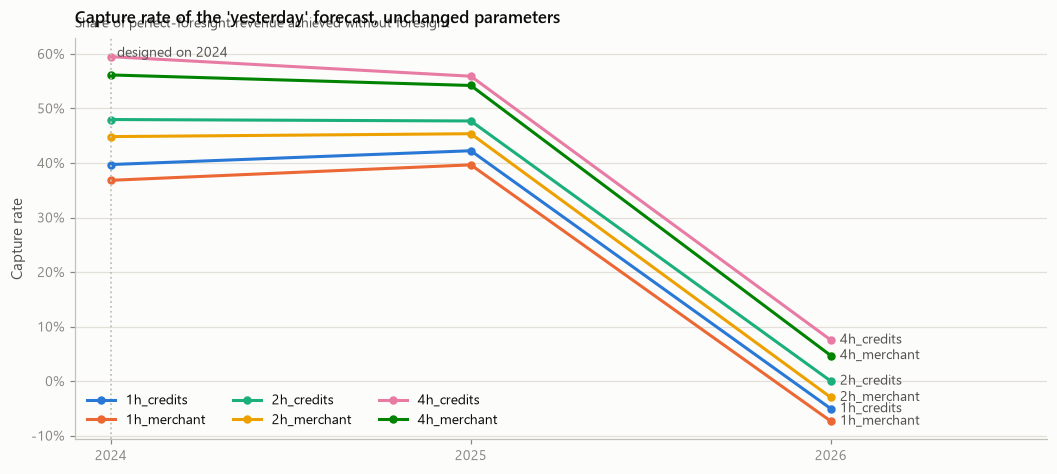

In [7]:
best = "yesterday"
fig, ax = viz.figure(9.5, 4.2)

subset = annual[(annual["strategy"] == best) & (annual["year"] >= 2024)]
for slot, case in enumerate(sorted(subset["case"].unique())):
    rows = subset[subset["case"] == case].sort_values("year")
    ax.plot(rows["year"], rows["capture_rate"], marker="o", color=viz.SERIES[slot], label=case)
    viz.label_last(ax, rows["year"].iloc[-1], rows["capture_rate"].iloc[-1], case, viz.SERIES[slot])

ax.axvline(strategies.DESIGN_YEAR, color=viz.AXIS, linestyle=":", linewidth=1.2)
ax.annotate(
    "designed on 2024",
    xy=(strategies.DESIGN_YEAR, ax.get_ylim()[1]),
    xytext=(4, -12),
    textcoords="offset points",
    fontsize=9,
    color=viz.INK_SECONDARY,
)
ax.set_xticks(sorted(subset["year"].unique()))
viz.percent(ax)
viz.finish(
    ax,
    f"Capture rate of the '{best}' forecast, unchanged parameters",
    subtitle="Share of perfect-foresight revenue achieved without foresight",
    ylabel="Capture rate",
)
ax.set_xlim(right=subset["year"].max() + 0.6)
ax.legend(loc="lower left", ncols=3)
plt.show()

## Revenue by duration and strategy, full period

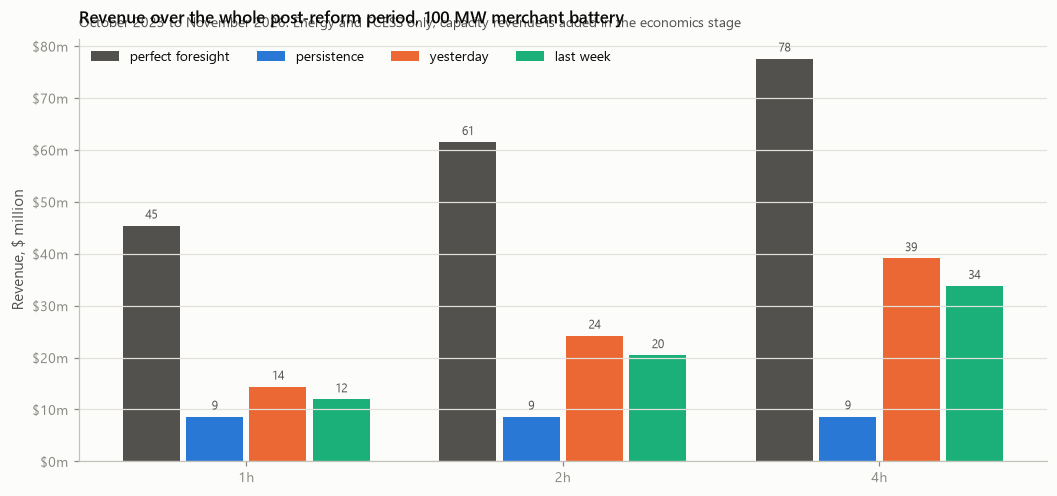

In [8]:
merchant = daily[daily["case"].str.endswith("merchant")]
period = (
    merchant.groupby(["case", "strategy"], observed=True)["total_revenue"].sum().unstack()
)
order = ["perfect_foresight", *strategies.NAIVE_FORECASTS]
period = period[order]

fig, ax = viz.figure(9.5, 4.4)
x = np.arange(len(period))
width = 0.2

for slot, strategy in enumerate(order):
    colour = viz.INK_SECONDARY if strategy == "perfect_foresight" else viz.SERIES[slot - 1]
    bars = ax.bar(
        x + (slot - 1.5) * width,
        period[strategy] / 1e6,
        width=width * 0.9,
        color=colour,
        label=strategy.replace("_", " "),
    )
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8, color=viz.INK_SECONDARY)

ax.set_xticks(x)
ax.set_xticklabels([c.replace("_merchant", "") for c in period.index])
viz.money(ax, unit="m")
viz.finish(
    ax,
    "Revenue over the whole post-reform period, 100 MW merchant battery",
    subtitle="October 2023 to November 2026. Energy and FCESS only; capacity revenue is added in the economics stage",
    ylabel="Revenue, $ million",
)
ax.legend(loc="upper left", ncols=4)
plt.show()

## How the opportunity moved through the period

Monthly revenue for the 2-hour merchant case. The collapse matters more than the capture rate: it is the direct consequence of batteries connecting.

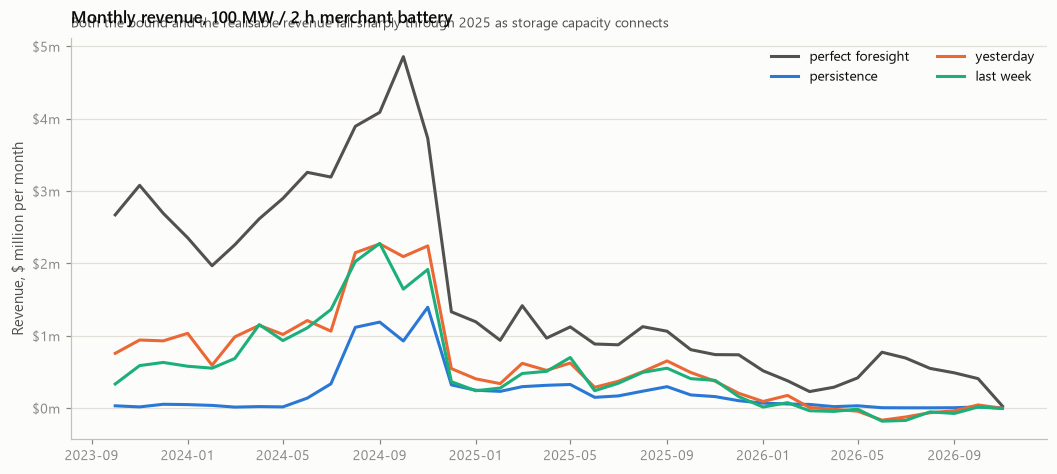

In [9]:
two_hour = daily[daily["case"] == "2h_merchant"].copy()
two_hour["month"] = two_hour["trading_date"].dt.to_period("M").dt.to_timestamp()
monthly = two_hour.pivot_table(
    index="month", columns="strategy", values="total_revenue", aggfunc="sum", observed=True
)

fig, ax = viz.figure(9.5, 4.2)
for slot, strategy in enumerate(order):
    colour = viz.INK_SECONDARY if strategy == "perfect_foresight" else viz.SERIES[slot - 1]
    ax.plot(monthly.index, monthly[strategy] / 1e6, color=colour, label=strategy.replace("_", " "))

viz.money(ax, unit="m")
viz.finish(
    ax,
    "Monthly revenue, 100 MW / 2 h merchant battery",
    subtitle="Both the bound and the realisable revenue fall sharply through 2025 as storage capacity connects",
    ylabel="Revenue, $ million per month",
)
ax.legend(loc="upper right", ncols=2)
plt.show()

## What the obligation costs

Holding Capacity Credits forbids charging inside the obligation window and requires enough energy to be held when it opens. The cost shown here is energy and FCESS revenue forgone; the Reserve Capacity revenue that pays for it is added in the economics stage.

In [10]:
obligation = (
    daily.groupby(["case", "strategy"], observed=True)["total_revenue"].sum().unstack(level=0)
)
rows = []
for duration in ("1h", "2h", "4h"):
    for strategy in order:
        free = obligation.loc[strategy, f"{duration}_merchant"]
        obliged = obligation.loc[strategy, f"{duration}_credits"]
        rows.append(
            {
                "duration": duration,
                "strategy": strategy,
                "merchant $m": free / 1e6,
                "with credits $m": obliged / 1e6,
                "obligation cost $m": (free - obliged) / 1e6,
                "obligation cost %": (free - obliged) / free,
            }
        )
pd.DataFrame(rows).set_index(["duration", "strategy"]).round(3)

merchant $m  with credits $m  obligation cost $m  obligation cost %
duration strategy                                                                              
1h       perfect_foresight       45.392           43.491               1.901              0.042
         persistence              8.595            9.055              -0.460             -0.054
         yesterday               14.375           15.134              -0.759             -0.053
         last_week               11.926           12.802              -0.876             -0.073
2h       perfect_foresight       61.486           59.241               2.245              0.037
         persistence              8.604           10.476              -1.872             -0.218
         yesterday               24.197           25.259              -1.062             -0.044
         last_week               20.431           21.641              -1.210             -0.059
4h       perfect_foresight       77.570           74.101               3.469              0.045
         persistence              8.645           13.698              -5.053             -0.584
         yesterday               39.105           39.870              -0.765             -0.020
         last_week               33.782           35.502              -1.720             -0.051

In [11]:
breaches = daily.groupby(["case", "strategy"], observed=True)["obligation_breaches"].max()
print("solves in which the battery could not meet the obligation window and dispatched anyway:")
breaches[breaches > 0].to_frame("breaches") if (breaches > 0).any() else print("  none")

solves in which the battery could not meet the obligation window and dispatched anyway:


,,breaches
case,strategy,
1h_credits,yesterday,1


## Summary for the write-up

In [12]:
headline = annual[(annual["year"].isin([2024, 2025])) & (annual["case"].str.endswith("merchant"))]
summary = headline.pivot_table(
    index=["year", "case"],
    columns="strategy",
    values=["$/MW-year", "capture_rate"],
    observed=True,
)
summary.round(3).to_csv(OUTPUTS / "capture_rate_summary.csv")
summary.round(3)

$/MW-year                                           capture_rate                                        
strategy           last_week perfect_foresight persistence   yesterday    last_week perfect_foresight persistence yesterday
year case                                                                                                                  
2024 1h_merchant   87494.841        273865.550   55753.053  100840.253        0.319               1.0       0.204     0.368
     2h_merchant  147230.308        367604.450   56005.237  164815.830        0.401               1.0       0.152     0.448
     4h_merchant  236269.166        461958.549   56301.199  259344.793        0.511               1.0       0.122     0.561
2025 1h_merchant   31941.221         88300.104   27173.364   35013.999        0.362               1.0       0.308     0.397
     2h_merchant   48015.040        119316.395   27151.562   54124.552        0.402               1.0       0.228     0.454
     4h_merchant   74310.042        153987.468   27134.943   83474.193        0.483               1.0       0.176     0.542